Частина 1

Імпорт бібліотек і завантаження даних

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from google.colab import files

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("Бібліотеки успішно імпортовано!")

uploaded = files.upload()
print("Завантажені файли:", list(uploaded.keys()))


Бібліотеки успішно імпортовано!


Saving CarPrice_Assignment.csv to CarPrice_Assignment (1).csv
Saving titanic.csv to titanic.csv
Завантажені файли: ['CarPrice_Assignment (1).csv', 'titanic.csv']


Перевірка даних

In [5]:

car_file = next(
    (name for name in uploaded if "carprice_assignment" in name.lower()),
    None
)

if car_file is None:
    raise FileNotFoundError(
        "Не знайдено CarPrice_Assignment.csv. Завантаж файл із Kaggle."
    )

df = pd.read_csv(car_file)

print("ПЕРШІ 5 РЯДКІВ:")
display(df.head())

print("\nРОЗМІР ДАТАСЕТА:", df.shape)
print("\nНАЗВИ СТОВПЦІВ:")
print(df.columns.tolist())

print("\nТИПИ ДАНИХ:")
print(df.dtypes)

print("\nПРОПУЩЕНІ ЗНАЧЕННЯ:")
print(df.isnull().sum())

print("\nКІЛЬКІСТЬ ДУБЛІКАТІВ:", df.duplicated().sum())

df = df.drop_duplicates().copy()
df.columns = df.columns.str.strip()

print("\nРОЗМІР ПІСЛЯ ВИДАЛЕННЯ ДУБЛІКАТІВ:", df.shape)


ПЕРШІ 5 РЯДКІВ:


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0



РОЗМІР ДАТАСЕТА: (205, 26)

НАЗВИ СТОВПЦІВ:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

ТИПИ ДАНИХ:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionratio    float64
horsepowe

Аналіз розподілів і викидів

ОПИС ЧИСЛОВИХ ОЗНАК:


,count,mean,std,min,25%,50%,75%,max
car_ID,205.0,103.000000,59.322565,1.00,52.00,103.00,154.00,205.00
symboling,205.0,0.834146,1.245307,-2.00,0.00,1.00,2.00,3.00
wheelbase,205.0,98.756585,6.021776,86.60,94.50,97.00,102.40,120.90
carlength,205.0,174.049268,12.337289,141.10,166.30,173.20,183.10,208.10
carwidth,205.0,65.907805,2.145204,60.30,64.10,65.50,66.90,72.30
carheight,205.0,53.724878,2.443522,47.80,52.00,54.10,55.50,59.80
curbweight,205.0,2555.565854,520.680204,1488.00,2145.00,2414.00,2935.00,4066.00
enginesize,205.0,126.907317,41.642693,61.00,97.00,120.00,141.00,326.00
boreratio,205.0,3.329756,0.270844,2.54,3.15,3.31,3.58,3.94
stroke,205.0,3.255415,0.313597,2.07,3.11,3.29,3.41,4.17



АСИМЕТРІЯ РОЗПОДІЛІВ:


,skewness
stroke,-0.689705
boreratio,0.020156
carheight,0.063123
peakrpm,0.075159
carlength,0.155954
symboling,0.211072
highwaympg,0.539997
citympg,0.663704
curbweight,0.681398
carwidth,0.904003


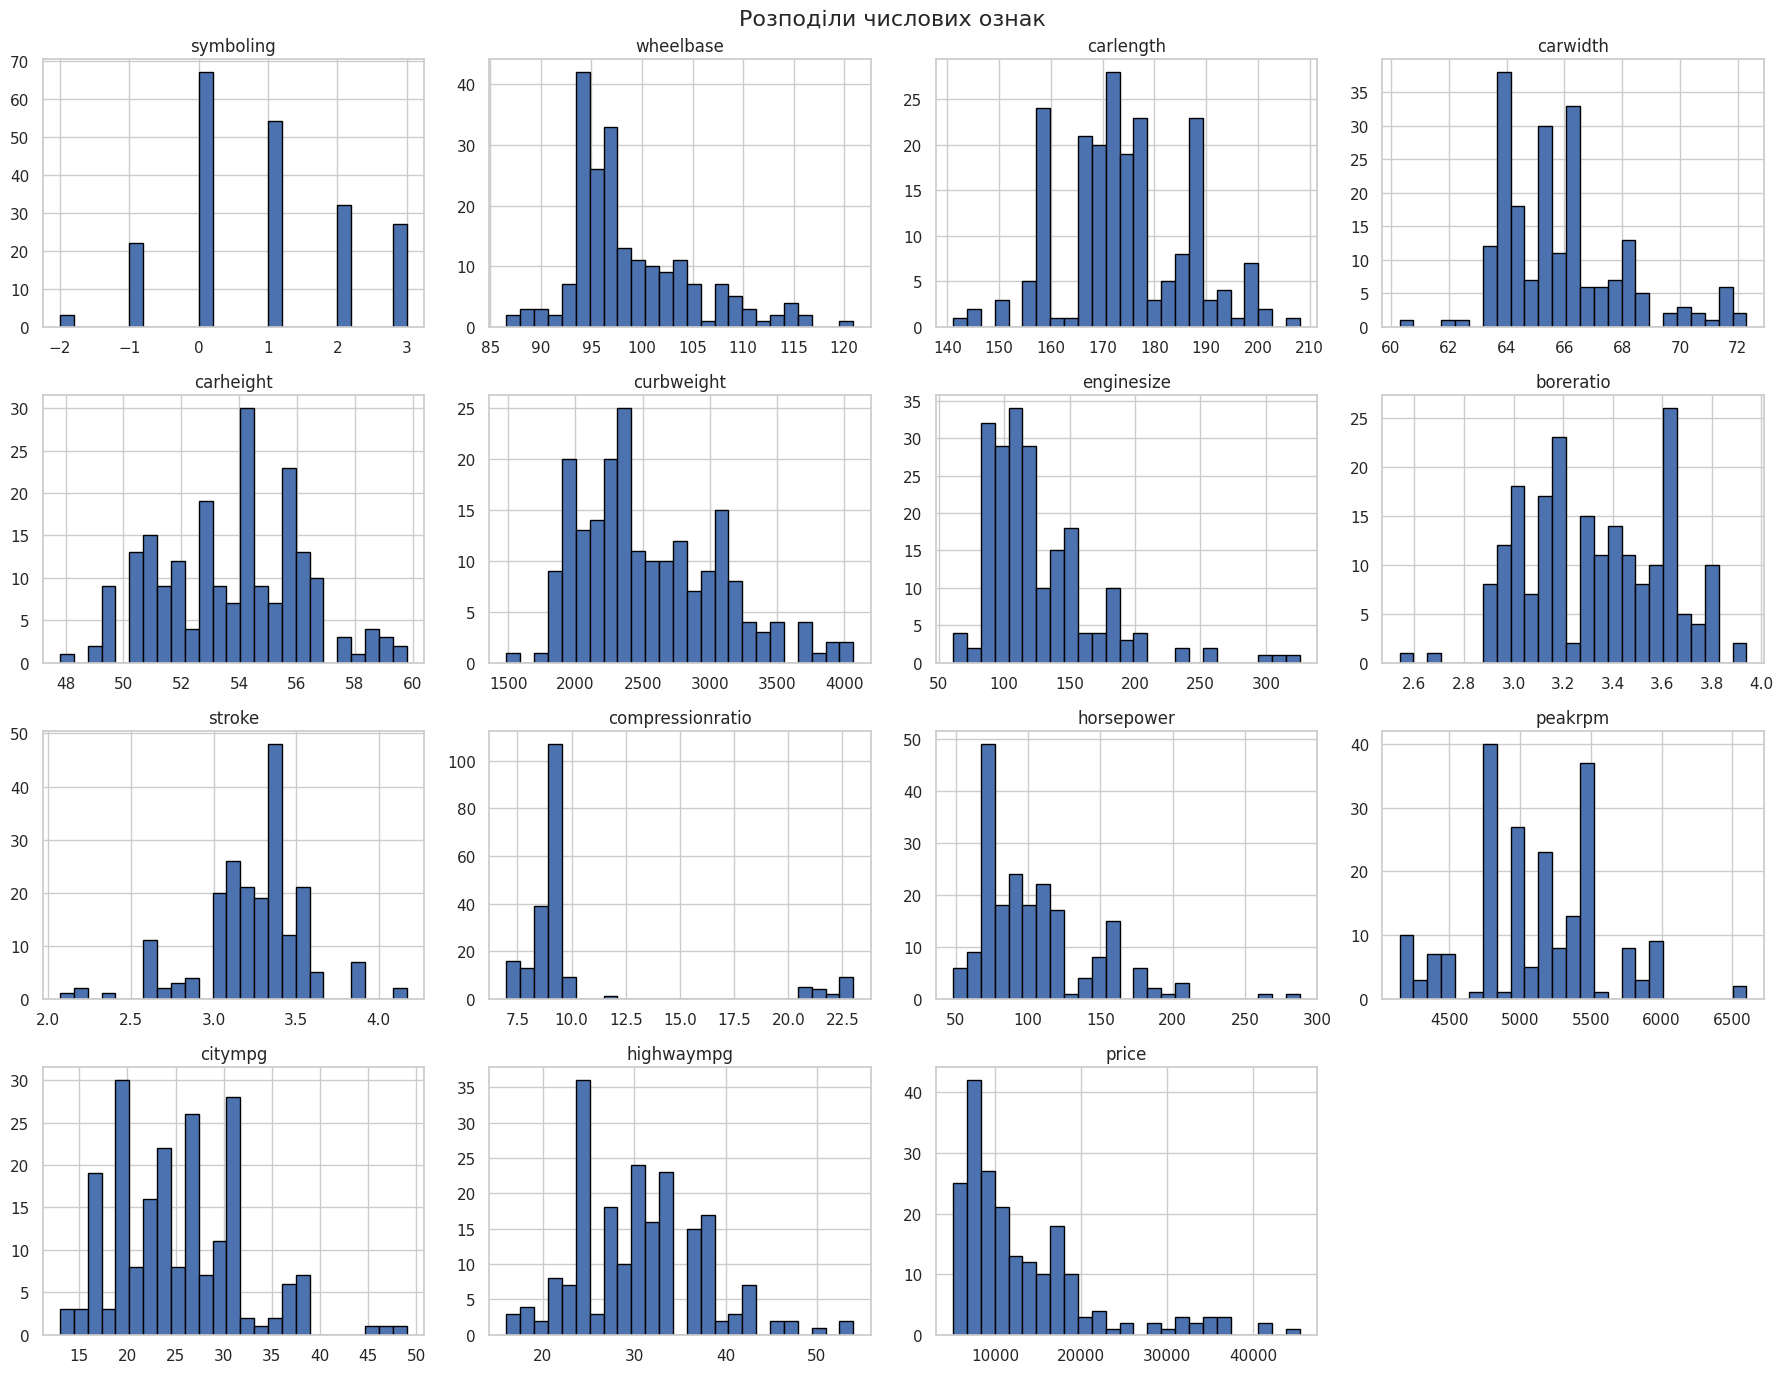

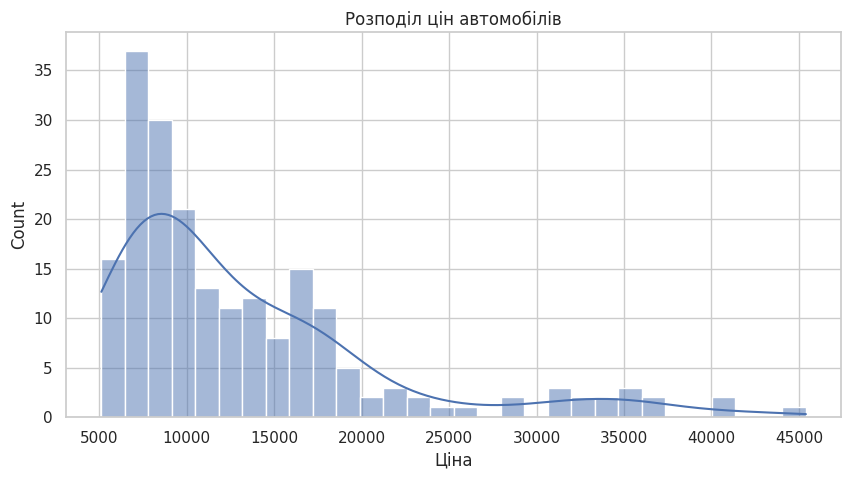

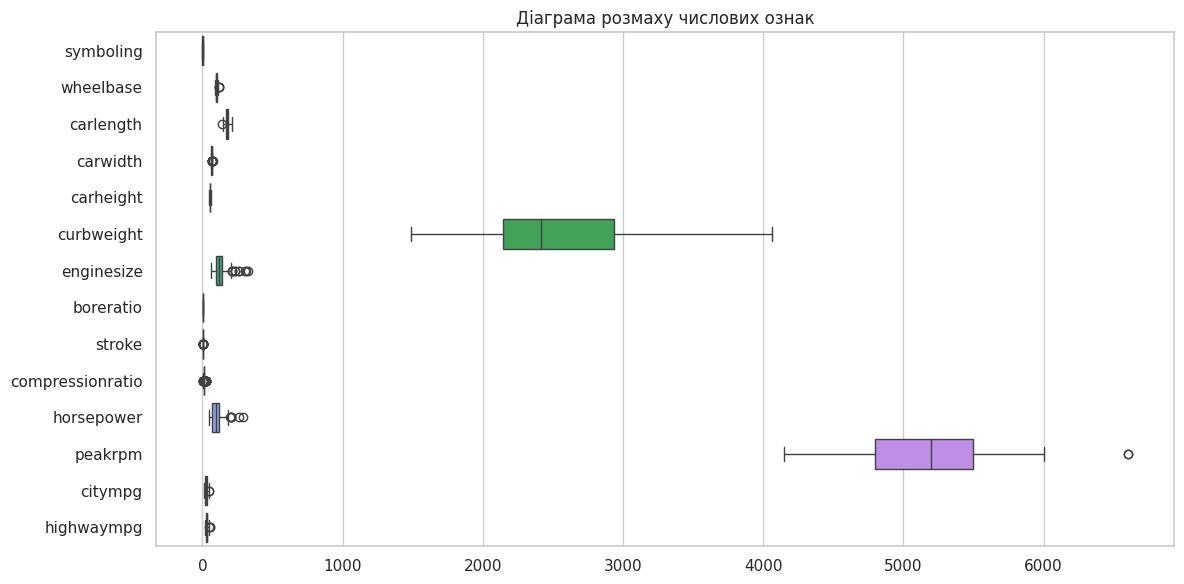

Кількість пропущених значень у ціні: 0


In [6]:

target_col = "price"

if target_col not in df.columns:
    raise ValueError("У датасеті не знайдено стовпець price.")

id_col = next(
    (c for c in df.columns if c.lower() == "car_id"),
    None
)

print("ОПИС ЧИСЛОВИХ ОЗНАК:")
display(df.describe().T)

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
feature_numeric = [
    c for c in numeric_cols if c not in [target_col, id_col]
]

print("\nАСИМЕТРІЯ РОЗПОДІЛІВ:")
display(df[feature_numeric + [target_col]].skew().sort_values().to_frame("skewness"))

df[feature_numeric + [target_col]].hist(
    figsize=(18, 14), bins=25, edgecolor="black"
)
plt.suptitle("Розподіли числових ознак", fontsize=16)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.histplot(df[target_col], kde=True, bins=30)
plt.title("Розподіл цін автомобілів")
plt.xlabel("Ціна")
plt.show()

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[feature_numeric], orient="h")
plt.title("Діаграма розмаху числових ознак")
plt.tight_layout()
plt.show()

print("Кількість пропущених значень у ціні:",
      df[target_col].isna().sum())


Обробка викидів і корельованих ознак

Форма датасета після обробки: (205, 26)


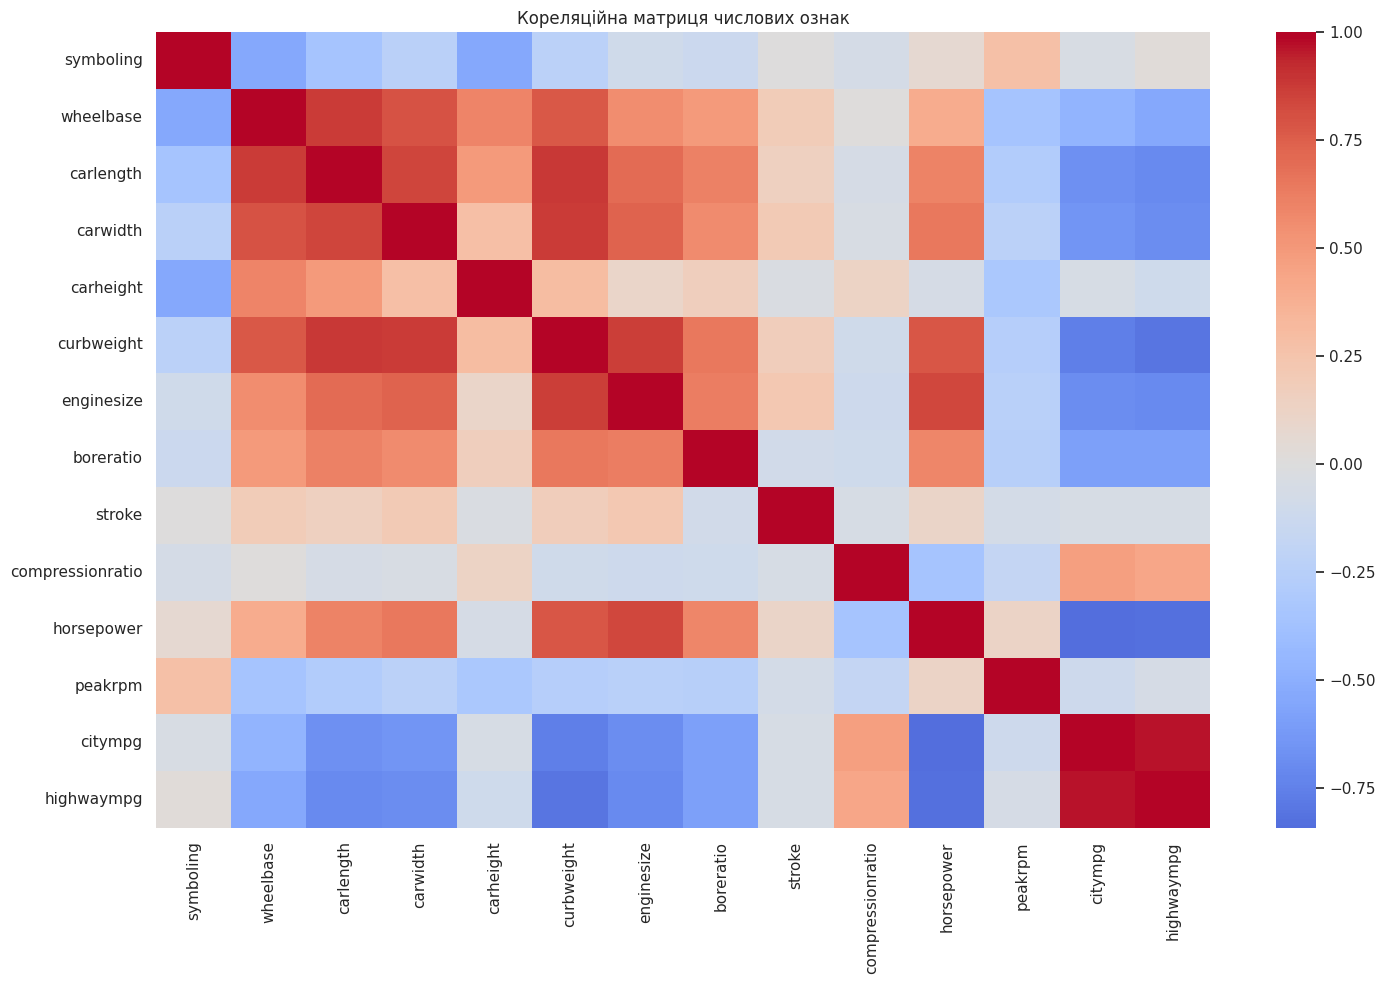

Видалені корельовані ознаки: ['carlength', 'curbweight', 'enginesize', 'highwaympg']


In [7]:

# Видаляємо рядки без цільової змінної
df = df.dropna(subset=[target_col]).copy()

# Прибираємо некоректні від'ємні ціни
df = df[df[target_col] > 0].copy()

# Для числових ознак обмежуємо крайні значення за правилом IQR
numeric_features = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in [target_col, id_col]
]

for col in numeric_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    if iqr > 0:
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        df[col] = df[col].clip(lower, upper)

print("Форма датасета після обробки:", df.shape)

# Кореляція між числовими ознаками
corr = df[numeric_features].corr()

plt.figure(figsize=(15, 10))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Кореляційна матриця числових ознак")
plt.tight_layout()
plt.show()

# Видаляємо одну ознаку з кожної сильно корельованої пари
upper = corr.abs().where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

to_drop = [
    col for col in upper.columns
    if any(upper[col] > 0.85)
]

print("Видалені корельовані ознаки:", to_drop)

df = df.drop(columns=to_drop)


Підготовка даних і симетризація розподілів

In [9]:

# Зберігаємо ID для подальшого прогнозу
if id_col is not None:
    ids = df[id_col].copy()
else:
    ids = pd.Series(df.index, index=df.index, name="ID")

# ID не використовуємо як ознаку для прогнозування
drop_cols = [target_col]
if id_col is not None:
    drop_cols.append(id_col)

X = df.drop(columns=drop_cols)
y = df[target_col]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Для числових ознак:
# заповнення пропусків, перетворення розподілу та масштабування
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("power", PowerTransformer(method="yeo-johnson")),
    ("scaler", StandardScaler())
])

# Для категоріальних ознак:
# заповнення пропусків та One-Hot Encoding
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Числові ознаки:", numeric_features)
print("Категоріальні ознаки:", categorical_features)
print("Кількість об'єктів:", len(X))

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, ids, test_size=0.2, random_state=42
)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)


Числові ознаки: ['symboling', 'wheelbase', 'carwidth', 'carheight', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg']
Категоріальні ознаки: ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']
Кількість об'єктів: 205
Розмір навчальної вибірки: (164, 20)
Розмір тестової вибірки: (41, 20)


Побудова шести регресійних моделей

In [10]:

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01, max_iter=20000),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),
    "SVR": SVR(kernel="rbf")
}

results = []
trained_models = {}
predictions = {}

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    trained_models[name] = pipe
    predictions[name] = pred

    results.append({
        "Модель": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df.round(3))

best_name = results_df.iloc[0]["Модель"]
best_model = trained_models[best_name]

print("Найкраща модель за RMSE:", best_name)


,Модель,MAE,RMSE,R2
3,Random Forest,1386.990,2252.756,0.936
4,Gradient Boosting,1949.250,3382.006,0.855
1,Ridge,2762.201,4115.540,0.785
0,Linear Regression,3723.422,5749.589,0.581
2,Lasso,3528.585,5856.721,0.565
5,SVR,5696.805,9318.533,-0.100


Найкраща модель за RMSE: Random Forest


Графіки справжніх і прогнозованих цін

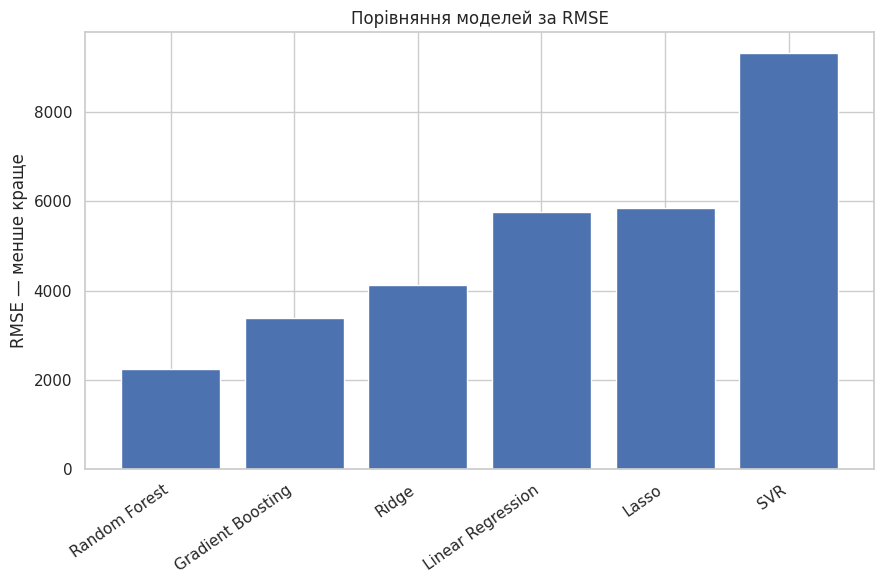

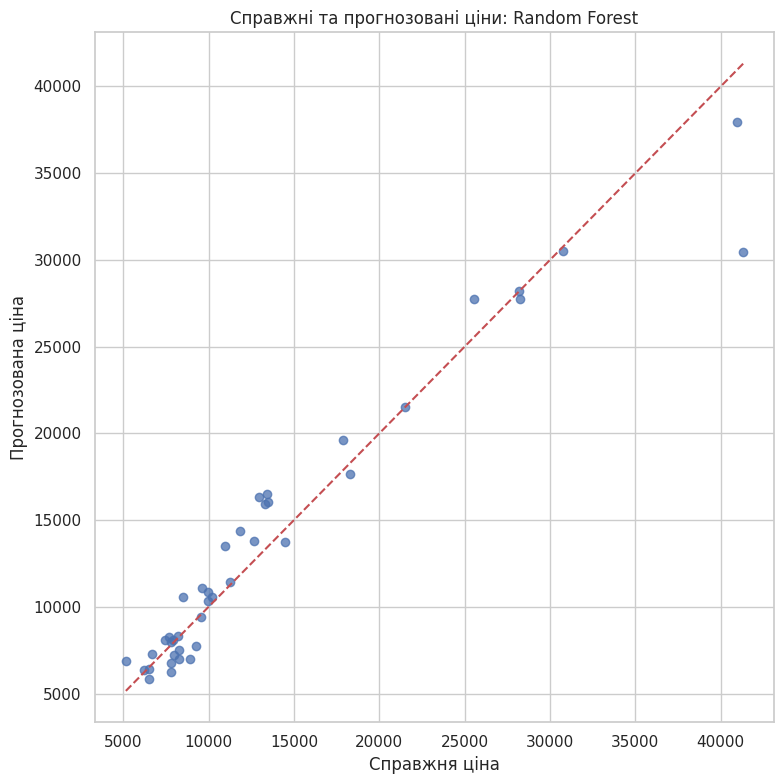

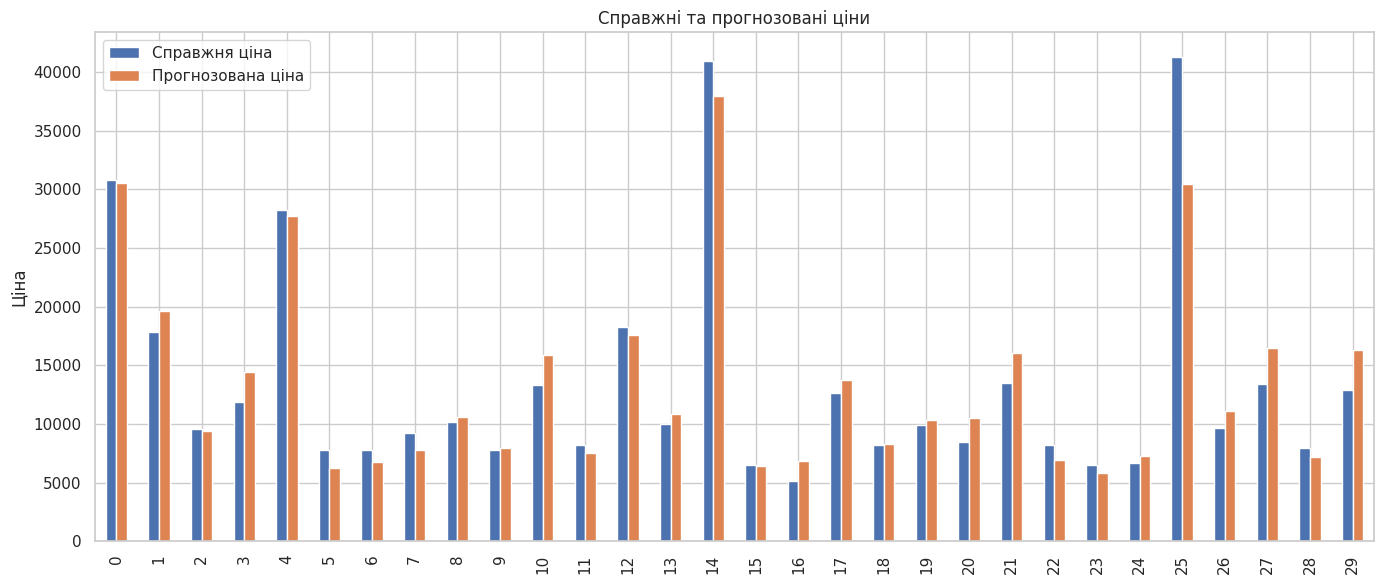

In [11]:

# Порівняння всіх моделей
plt.figure(figsize=(9, 6))
plt.bar(results_df["Модель"], results_df["RMSE"])
plt.title("Порівняння моделей за RMSE")
plt.ylabel("RMSE — менше краще")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Графік справжніх і прогнозованих значень для найкращої моделі
best_pred = predictions[best_name]

plt.figure(figsize=(8, 8))
plt.scatter(y_test, best_pred, alpha=0.75)

min_val = min(y_test.min(), best_pred.min())
max_val = max(y_test.max(), best_pred.max())

plt.plot([min_val, max_val], [min_val, max_val], "r--")
plt.xlabel("Справжня ціна")
plt.ylabel("Прогнозована ціна")
plt.title(f"Справжні та прогнозовані ціни: {best_name}")
plt.tight_layout()
plt.show()

# Порівняння перших 30 об'єктів тестової вибірки
comparison = pd.DataFrame({
    "Справжня ціна": y_test.values,
    "Прогнозована ціна": best_pred
}).head(30)

comparison.plot(kind="bar", figsize=(14, 6))
plt.title("Справжні та прогнозовані ціни")
plt.ylabel("Ціна")
plt.tight_layout()
plt.show()


Прогноз ціни для 10 випадкових ID за допомогою Random Forest

In [12]:

rf_model = trained_models["Random Forest"]

n = min(10, len(X_test))
rng = np.random.default_rng(42)
random_positions = rng.choice(len(X_test), size=n, replace=False)

X_random = X_test.iloc[random_positions]
y_random = y_test.iloc[random_positions]
id_random = id_test.iloc[random_positions]

rf_predictions = rf_model.predict(X_random)

random_results = pd.DataFrame({
    "ID автомобіля": id_random.values,
    "Справжня ціна": y_random.values,
    "Прогноз Random Forest": rf_predictions
})

random_results["Абсолютна помилка"] = abs(
    random_results["Справжня ціна"]
    - random_results["Прогноз Random Forest"]
)

display(random_results.round(2))


,ID автомобіля,Справжня ціна,Прогноз Random Forest,Абсолютна помилка
0,133,11850.0,14397.33,2547.33
1,17,41315.0,30468.54,10846.46
2,101,9549.0,9436.07,112.93
3,99,8249.0,6977.70,1271.30
4,153,6488.0,6395.88,92.12
5,70,28176.0,28208.85,32.85
6,196,13415.0,16484.23,3069.23
7,147,7463.0,8058.81,595.81
8,148,10198.0,10578.73,380.73
9,121,6229.0,6356.70,127.70


Висновки до регресії

In [14]:

print("Кількість записів після очищення:", len(df))
print("Кількість ознак після видалення кореляцій:", X.shape[1])
print("Найкраща модель за RMSE:", best_name)
print("MAE:", round(
    mean_absolute_error(y_test, predictions[best_name]), 3
))
print("RMSE:", round(
    np.sqrt(mean_squared_error(y_test, predictions[best_name])), 3
))
print("R2:", round(r2_score(y_test, predictions[best_name]), 3))

Кількість записів після очищення: 205
Кількість ознак після видалення кореляцій: 20
Найкраща модель за RMSE: Random Forest
MAE: 1386.99
RMSE: 2252.756
R2: 0.936


Висновок: найкращою за RMSE є модель із найменшою середньою квадратичною помилкою на тестових даних. Результат залежить від очищення даних, ознак і параметрів моделей

Частина 2


Завантаження та попередній аналіз

In [15]:
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report
)

cancer = load_breast_cancer(as_frame=True)

cancer_df = cancer.data.copy()
cancer_df["target"] = cancer.target

print("ПЕРШІ 5 РЯДКІВ:")
display(cancer_df.head())

print("\nРОЗМІР:", cancer_df.shape)
print("\nНАЗВИ СТОВПЦІВ:")
print(cancer_df.columns.tolist())

print("\nТИПИ ДАНИХ:")
print(cancer_df.dtypes)

print("\nПРОПУЩЕНІ ЗНАЧЕННЯ:")
print(cancer_df.isnull().sum())

print("\nКІЛЬКІСТЬ ДУБЛІКАТІВ:", cancer_df.duplicated().sum())

print("\nРОЗПОДІЛ КЛАСІВ:")
print(cancer_df["target"].value_counts())

print("\nНАЗВИ КЛАСІВ:", cancer.target_names)


ПЕРШІ 5 РЯДКІВ:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



РОЗМІР: (569, 31)

НАЗВИ СТОВПЦІВ:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']

ТИПИ ДАНИХ:
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error   

Розподіл даних і підбір параметрів

In [16]:

X_cancer = cancer.data
y_cancer = cancer.target

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cancer,
    y_cancer,
    test_size=0.2,
    random_state=42,
    stratify=y_cancer
)

cancer_models = {
    "Logistic Regression": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=10000))
        ]),
        {
            "model__C": [0.1, 1, 10]
        }
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {
            "max_depth": [3, 5, 10, None],
            "min_samples_split": [2, 5, 10]
        }
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {
            "n_estimators": [100, 200],
            "max_depth": [None, 5, 10],
            "min_samples_split": [2, 5]
        }
    )
}

cancer_searches = {}
cancer_results = []
cancer_predictions = {}

for name, (model, params) in cancer_models.items():
    search = GridSearchCV(
        model, params, cv=5, scoring="accuracy", n_jobs=-1
    )
    search.fit(Xc_train, yc_train)

    pred = search.predict(Xc_test)
    cancer_searches[name] = search
    cancer_predictions[name] = pred

    cancer_results.append({
        "Модель": name,
        "Accuracy": accuracy_score(yc_test, pred),
        "Найкращі параметри": search.best_params_
    })

cancer_results_df = pd.DataFrame(cancer_results)
display(cancer_results_df)


,Модель,Accuracy,Найкращі параметри
0,Logistic Regression,0.973684,{'model__C': 0.1}
1,Decision Tree,0.921053,"{'max_depth': 5, 'min_samples_split': 5}"
2,Random Forest,0.956140,"{'max_depth': None, 'min_samples_split': 2, 'n..."


Метрики, матриці помилок і звіти


МОДЕЛЬ: Logistic Regression
Найкращі параметри: {'model__C': 0.1}
Accuracy: 0.9737

Матриця помилок:
[[40  2]
 [ 1 71]]

Звіт класифікації:
              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        42
      benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



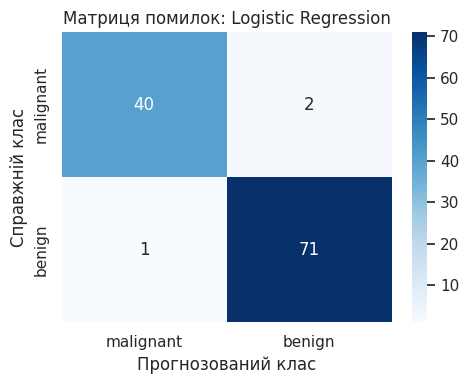


МОДЕЛЬ: Decision Tree
Найкращі параметри: {'max_depth': 5, 'min_samples_split': 5}
Accuracy: 0.9211

Матриця помилок:
[[39  3]
 [ 6 66]]

Звіт класифікації:
              precision    recall  f1-score   support

   malignant       0.87      0.93      0.90        42
      benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



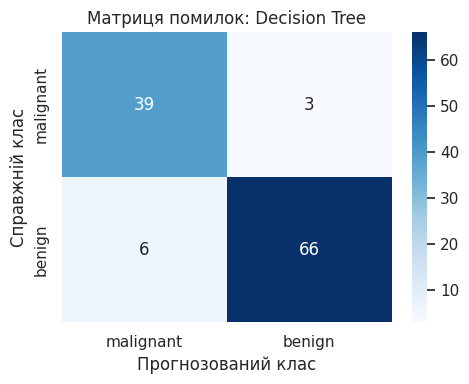


МОДЕЛЬ: Random Forest
Найкращі параметри: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Accuracy: 0.9561

Матриця помилок:
[[39  3]
 [ 2 70]]

Звіт класифікації:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



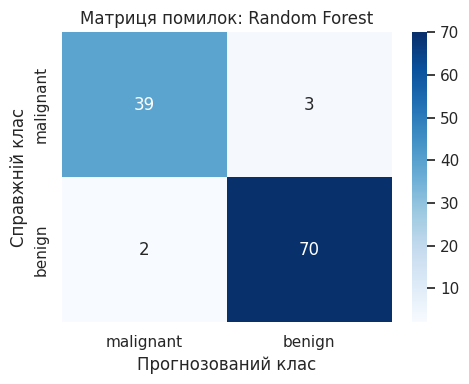

In [17]:
for name, search in cancer_searches.items():
    pred = cancer_predictions[name]

    print("\n" + "=" * 60)
    print("МОДЕЛЬ:", name)
    print("Найкращі параметри:", search.best_params_)
    print("Accuracy:", round(accuracy_score(yc_test, pred), 4))

    print("\nМатриця помилок:")
    cm = confusion_matrix(yc_test, pred)
    print(cm)

    print("\nЗвіт класифікації:")
    print(classification_report(
        yc_test, pred,
        labels=[0, 1],
        target_names=["malignant", "benign"],
        zero_division=0
    ))

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["malignant", "benign"],
        yticklabels=["malignant", "benign"]
    )
    plt.xlabel("Прогнозований клас")
    plt.ylabel("Справжній клас")
    plt.title(f"Матриця помилок: {name}")
    plt.tight_layout()
    plt.show()


Найкраща модель і прогноз тестових випадків

In [19]:

best_cancer_name = max(
    cancer_results,
    key=lambda row: row["Accuracy"]
)["Модель"]

best_cancer_model = cancer_searches[best_cancer_name]
best_cancer_pred = cancer_predictions[best_cancer_name]

print("НАЙКРАЩА МОДЕЛЬ:", best_cancer_name)
print("Accuracy:", round(
    accuracy_score(yc_test, best_cancer_pred), 4
))

cancer_prediction_table = pd.DataFrame({
    "Справжній клас": yc_test.values,
    "Прогнозований клас": best_cancer_pred
})

cancer_prediction_table["Справжня назва"] = (
    cancer_prediction_table["Справжній клас"]
    .map({0: "malignant", 1: "benign"})
)
cancer_prediction_table["Прогнозована назва"] = (
    cancer_prediction_table["Прогнозований клас"]
    .map({0: "malignant", 1: "benign"})
)

display(cancer_prediction_table.head(20))

print("\nВИСНОВОК:")
print(
    "Найкраща модель за Accuracy:", best_cancer_name,
    ". Остаточну оцінку потрібно робити за Accuracy, "
    "precision, recall і F1-score."
)


НАЙКРАЩА МОДЕЛЬ: Logistic Regression
Accuracy: 0.9737


,Справжній клас,Прогнозований клас,Справжня назва,Прогнозована назва
0,0,0,malignant,malignant
1,1,1,benign,benign
2,0,0,malignant,malignant
3,1,1,benign,benign
4,0,0,malignant,malignant
5,1,1,benign,benign
6,1,1,benign,benign
7,0,0,malignant,malignant
8,0,0,malignant,malignant
9,0,0,malignant,malignant



ВИСНОВОК:
Найкраща модель за Accuracy: Logistic Regression . Остаточну оцінку потрібно робити за Accuracy, precision, recall і F1-score.


Частина 3 Класифікація Titanic

Завантаження й аналіз даних

In [20]:
# Шукаємо Titanic серед файлів, завантажених у першій комірці
titanic_file = next(
    (
        name for name in uploaded
        if "titanic" in name.lower()
        and "carprice_assignment" not in name.lower()
    ),
    None
)

if titanic_file is None:
    # Якщо файл має іншу назву, перевіряємо CSV-файли
    for name in uploaded:
        if name.lower().endswith(".csv") and name != car_file:
            candidate = pd.read_csv(name, nrows=5)
            if "Survived" in candidate.columns:
                titanic_file = name
                break

if titanic_file is None:
    raise FileNotFoundError(
        "Не знайдено titanic.csv. Завантаж файл Titanic."
    )

titanic_df = pd.read_csv(titanic_file)

# Прибираємо зайві пробіли в назвах стовпців
titanic_df.columns = titanic_df.columns.str.strip()

print("ПЕРШІ 5 РЯДКІВ:")
display(titanic_df.head())

print("\nРОЗМІР ДАТАСЕТА:", titanic_df.shape)
print("\nНАЗВИ СТОВПЦІВ:")
print(titanic_df.columns.tolist())

print("\nТИПИ ДАНИХ:")
print(titanic_df.dtypes)

print("\nПРОПУЩЕНІ ЗНАЧЕННЯ:")
print(titanic_df.isnull().sum())

print("\nДУБЛІКАТИ:", titanic_df.duplicated().sum())

print("\nРОЗПОДІЛ ЦІЛЬОВОЇ ЗМІННОЇ:")
if "Survived" in titanic_df.columns:
    print(titanic_df["Survived"].value_counts())
else:
    raise ValueError(
        "У Titanic не знайдено стовпець Survived. "
        "Перевір назву цільової змінної."
    )


ПЕРШІ 5 РЯДКІВ:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



РОЗМІР ДАТАСЕТА: (891, 12)

НАЗВИ СТОВПЦІВ:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

ТИПИ ДАНИХ:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

ПРОПУЩЕНІ ЗНАЧЕННЯ:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

ДУБЛІКАТИ: 0

РОЗПОДІЛ ЦІЛЬОВОЇ ЗМІННОЇ:
Survived
0    549
1    342
Name: count, dtype: int64


Підготовка даних

In [21]:

titanic_df = titanic_df.drop_duplicates().copy()
titanic_df = titanic_df.dropna(subset=["Survived"]).copy()

# Цільова змінна має бути числовою
titanic_df["Survived"] = pd.to_numeric(
    titanic_df["Survived"], errors="coerce"
)
titanic_df = titanic_df.dropna(subset=["Survived"]).copy()
titanic_df["Survived"] = titanic_df["Survived"].astype(int)

# Зберігаємо ID для таблиці прогнозів
id_candidates = [
    c for c in titanic_df.columns
    if c.lower() in ["passengerid", "passenger_id", "id"]
]

if id_candidates:
    titanic_ids = titanic_df[id_candidates[0]].copy()
else:
    titanic_ids = pd.Series(
        titanic_df.index, index=titanic_df.index, name="ID"
    )

# Видаляємо цільову змінну та ідентифікатор із вхідних ознак
drop_cols = ["Survived"] + id_candidates
X_titanic = titanic_df.drop(
    columns=drop_cols, errors="ignore"
)
y_titanic = titanic_df["Survived"]

# Видаляємо колонки, які повністю порожні
X_titanic = X_titanic.dropna(axis=1, how="all")

# Визначаємо числові та категоріальні ознаки
titanic_numeric = X_titanic.select_dtypes(
    include=np.number
).columns.tolist()

titanic_categorical = X_titanic.select_dtypes(
    exclude=np.number
).columns.tolist()

titanic_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

titanic_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

titanic_preprocessor = ColumnTransformer([
    ("num", titanic_numeric_pipeline, titanic_numeric),
    ("cat", titanic_categorical_pipeline, titanic_categorical)
])

Xt_train, Xt_test, yt_train, yt_test, idt_train, idt_test = (
    train_test_split(
        X_titanic,
        y_titanic,
        titanic_ids,
        test_size=0.2,
        random_state=42,
        stratify=y_titanic
    )
)

print("Розмір навчальної вибірки:", Xt_train.shape)
print("Розмір тестової вибірки:", Xt_test.shape)
print("Числові ознаки:", titanic_numeric)
print("Категоріальні ознаки:", titanic_categorical)


Розмір навчальної вибірки: (712, 10)
Розмір тестової вибірки: (179, 10)
Числові ознаки: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Категоріальні ознаки: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


Три класифікатори та GridSearchCV

In [22]:

titanic_models = {
    "Logistic Regression": (
        Pipeline([
            ("prep", titanic_preprocessor),
            ("model", LogisticRegression(max_iter=5000))
        ]),
        {
            "model__C": [0.1, 1, 10]
        }
    ),
    "Decision Tree": (
        Pipeline([
            ("prep", titanic_preprocessor),
            ("model", DecisionTreeClassifier(random_state=42))
        ]),
        {
            "model__max_depth": [3, 5, 10, None],
            "model__min_samples_split": [2, 5, 10]
        }
    ),
    "Random Forest": (
        Pipeline([
            ("prep", titanic_preprocessor),
            ("model", RandomForestClassifier(random_state=42))
        ]),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 5, 10],
            "model__min_samples_split": [2, 5]
        }
    )
}

titanic_searches = {}
titanic_predictions = {}
titanic_results = []

for name, (pipe, params) in titanic_models.items():
    search = GridSearchCV(
        pipe, params, cv=5, scoring="accuracy", n_jobs=-1
    )
    search.fit(Xt_train, yt_train)

    pred = search.predict(Xt_test)

    titanic_searches[name] = search
    titanic_predictions[name] = pred

    titanic_results.append({
        "Модель": name,
        "Accuracy": accuracy_score(yt_test, pred),
        "Найкращі параметри": search.best_params_
    })

titanic_results_df = pd.DataFrame(titanic_results)
display(titanic_results_df)


,Модель,Accuracy,Найкращі параметри
0,Logistic Regression,0.804469,{'model__C': 10}
1,Decision Tree,0.798883,"{'model__max_depth': 10, 'model__min_samples_s..."
2,Random Forest,0.821229,"{'model__max_depth': None, 'model__min_samples..."


Метрики та матриці помилок


МОДЕЛЬ: Logistic Regression
Найкращі параметри: {'model__C': 10}
Accuracy: 0.8045

Матриця помилок:
[[94 16]
 [19 50]]

Звіт класифікації:
              precision    recall  f1-score   support

    Не вижив       0.83      0.85      0.84       110
       Вижив       0.76      0.72      0.74        69

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



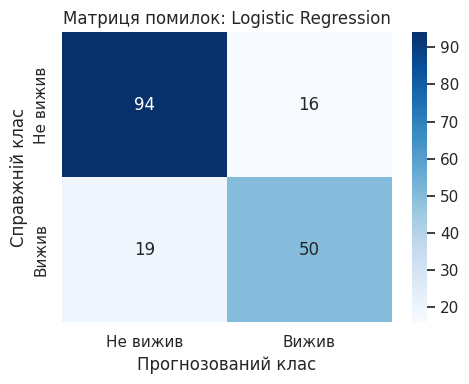


МОДЕЛЬ: Decision Tree
Найкращі параметри: {'model__max_depth': 10, 'model__min_samples_split': 5}
Accuracy: 0.7989

Матриця помилок:
[[99 11]
 [25 44]]

Звіт класифікації:
              precision    recall  f1-score   support

    Не вижив       0.80      0.90      0.85       110
       Вижив       0.80      0.64      0.71        69

    accuracy                           0.80       179
   macro avg       0.80      0.77      0.78       179
weighted avg       0.80      0.80      0.79       179



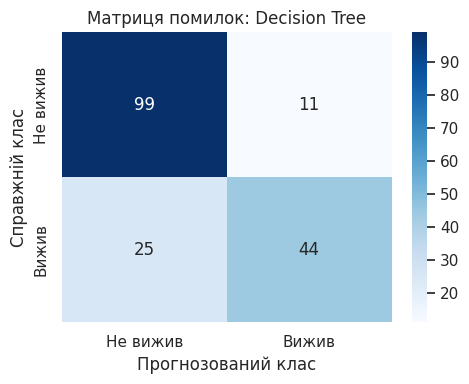


МОДЕЛЬ: Random Forest
Найкращі параметри: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Accuracy: 0.8212

Матриця помилок:
[[103   7]
 [ 25  44]]

Звіт класифікації:
              precision    recall  f1-score   support

    Не вижив       0.80      0.94      0.87       110
       Вижив       0.86      0.64      0.73        69

    accuracy                           0.82       179
   macro avg       0.83      0.79      0.80       179
weighted avg       0.83      0.82      0.81       179



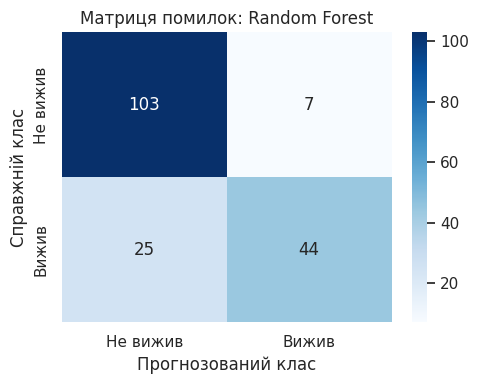

In [23]:

for name, search in titanic_searches.items():
    pred = titanic_predictions[name]

    print("\n" + "=" * 60)
    print("МОДЕЛЬ:", name)
    print("Найкращі параметри:", search.best_params_)
    print("Accuracy:", round(accuracy_score(yt_test, pred), 4))

    print("\nМатриця помилок:")
    cm = confusion_matrix(yt_test, pred, labels=[0, 1])
    print(cm)

    print("\nЗвіт класифікації:")
    print(classification_report(
        yt_test, pred,
        labels=[0, 1],
        target_names=["Не вижив", "Вижив"],
        zero_division=0
    ))

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Не вижив", "Вижив"],
        yticklabels=["Не вижив", "Вижив"]
    )
    plt.xlabel("Прогнозований клас")
    plt.ylabel("Справжній клас")
    plt.title(f"Матриця помилок: {name}")
    plt.tight_layout()
    plt.show()


Вибір найкращої моделі та прогноз для 10 пасажирів

In [24]:

best_titanic_name = max(
    titanic_results,
    key=lambda row: row["Accuracy"]
)["Модель"]

best_titanic_model = titanic_searches[best_titanic_name]

print("НАЙКРАЩА МОДЕЛЬ:", best_titanic_name)
print("Accuracy:", round(
    accuracy_score(
        yt_test, titanic_predictions[best_titanic_name]
    ), 4
))

n = min(10, len(Xt_test))
rng = np.random.default_rng(42)
positions = rng.choice(len(Xt_test), size=n, replace=False)

X_ten = Xt_test.iloc[positions]
y_ten = yt_test.iloc[positions]
id_ten = idt_test.iloc[positions]

pred_ten = best_titanic_model.predict(X_ten)

ten_results = pd.DataFrame({
    "ID пасажира": id_ten.values,
    "Справжнє значення": y_ten.values,
    "Прогноз": pred_ten
})

ten_results["Результат"] = ten_results["Прогноз"].map({
    0: "Не вижив",
    1: "Вижив"
})

ten_results["Правильність"] = (
    ten_results["Справжнє значення"] == ten_results["Прогноз"]
)

display(ten_results)


НАЙКРАЩА МОДЕЛЬ: Random Forest
Accuracy: 0.8212


,ID пасажира,Справжнє значення,Прогноз,Результат,Правильність
0,92,0,0,Не вижив,True
1,187,1,1,Вижив,True
2,704,0,0,Не вижив,True
3,147,1,0,Не вижив,False
4,154,0,0,Не вижив,True
5,144,0,0,Не вижив,True
6,542,0,0,Не вижив,True
7,486,0,0,Не вижив,True
8,870,1,0,Не вижив,False
9,805,1,0,Не вижив,False


Висновки до класифікації Titanic

In [25]:
print("Найкраща модель:", best_titanic_name)
print(
    "Accuracy:",
    round(
        accuracy_score(
            yt_test, titanic_predictions[best_titanic_name]
        ), 4
    )
)


Найкраща модель: Random Forest
Accuracy: 0.8212


Модель навчається на характеристиках пасажирів і прогнозує цільову змінну Survived. Якість оцінено за тестовою вибіркою, матрицею помилок та звітом класифікації